In [1]:
import io
import csv
import numpy as np
import pandas as pd
from visualise import visualize_network, visualise_flow

In [3]:
df = pd.read_csv("../indians_diabetes_dataset.csv")
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [4]:
# Remove missing values
# Missing values are stored as `0` in the dataset
cols = ["BloodPressure", "Glucose", "BMI"]
df = df[(df[cols] != 0).all(axis=1)]
df.head()


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [5]:
# Select only five features
feature_names = ["Pregnancies", "Glucose", "BloodPressure", "BMI", "Age"]

target_name = "Outcome"

In [6]:
X = df[feature_names]
y = df[target_name]

print("Shape of X: ", X.shape)
print("Shape of y: ", y.shape)

Shape of X:  (724, 5)
Shape of y:  (724,)


In [7]:
print(X.head(10))

    Pregnancies  Glucose  BloodPressure   BMI  Age
0             6      148             72  33.6   50
1             1       85             66  26.6   31
2             8      183             64  23.3   32
3             1       89             66  28.1   21
4             0      137             40  43.1   33
5             5      116             74  25.6   30
6             3       78             50  31.0   26
8             2      197             70  30.5   53
10            4      110             92  37.6   30
11           10      168             74  38.0   34


In [8]:
print(y[:10])

0     1
1     0
2     1
3     0
4     1
5     0
6     1
8     1
10    0
11    1
Name: Outcome, dtype: int64


In [9]:
X.info()

<class 'pandas.DataFrame'>
Index: 724 entries, 0 to 767
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Pregnancies    724 non-null    int64  
 1   Glucose        724 non-null    int64  
 2   BloodPressure  724 non-null    int64  
 3   BMI            724 non-null    float64
 4   Age            724 non-null    int64  
dtypes: float64(1), int64(4)
memory usage: 33.9 KB


In [10]:
X.describe().T

,count,mean,std,min,25%,50%,75%,max
Pregnancies,724.0,3.866022,3.362803,0.0,1.00,3.0,6.0,17.0
Glucose,724.0,121.882597,30.750030,44.0,99.75,117.0,142.0,199.0
BloodPressure,724.0,72.400552,12.379870,24.0,64.00,72.0,80.0,122.0
BMI,724.0,32.467127,6.888941,18.2,27.50,32.4,36.6,67.1
Age,724.0,33.350829,11.765393,21.0,24.00,29.0,41.0,81.0


In [11]:
# Split the dataset into train and test
# 80% for training and 20% for testing

# SHuffle the observation before splitting
np.random.seed(42)
indices = np.random.permutation(len(X))

X = X.values[indices]
y = y.values[indices]

In [12]:
# Now split the dataset after shuffling

split_index = int(0.8*len(X))
print(split_index)

579


In [13]:
# Now split
X_train = X[:split_index]
y_train = y[:split_index]

X_test = X[split_index:]
y_test = y[split_index:]


In [14]:
print(f"X_train shape: {X_train.shape}")
print(f"y_train shape: {y_train.shape}")

print(f"\nX_test shape: {X_test.shape}")
print(f"y_test shape: {y_test.shape}")

X_train shape: (579, 5)
y_train shape: (579,)

X_test shape: (145, 5)
y_test shape: (145,)


In [15]:
## Feature Standardisation using Z-scores
# X_scaled = (X - mean)/standard_deviation

# After standardisation, the features should have a mean of 0 and standard deviation of 1

mean_u = np.mean(X_train, axis=0)
std = np.std(X_train, axis=0)

X_train = (X_train - mean_u) / std
X_test = (X_test - mean_u) / std

print("Train mean: ", [round(val) for val in np.mean(X_train, axis=0)])
print("Train std: ", [round(val) for val in np.std(X_train, axis=0)])

print("Test mean: ", [round(val) for val in np.mean(X_test, axis=0)])
print("Test std: ", [round(val) for val in np.std(X_test, axis=0)])

Train mean:  [0, 0, 0, 0, 0]
Train std:  [1, 1, 1, 1, 1]
Test mean:  [0, 0, 0, 0, 0]
Test std:  [1, 1, 1, 1, 1]


In [16]:
# Initialise the neural network parameters
# NETWORK: 5 -> 5 -> 5 -> 1

# Weight Initialisation
# For the ReLU layers, HE initialisation will be used.
# W ~= N(0, 2/n_in)
# This means the weights are randomly sampled from a normal distribution with std = (2/n_in)**0.5

# NOTE: n_in is the number of input features

# Shape of first  hidden layer weight matrix: W1.shape = 5x5
# Shape of second hidden layer weight matrix: W2.shape = 5x5

# For the output layer, a smaller Xavier-style initialisation will be used

# W3 ~= N(0, 1/n_in)

In [17]:
# Initialise weights and biases
np.random.seed(42)

# First hidden layer weights initialised
n_in = 5
w1 = np.random.randn(n_in, n_in) * np.sqrt(2/n_in)
b1 = np.zeros((1, n_in))
print("Weights")
print(w1)

print("Biases")
print(b1)

Weights
[[ 0.31414961 -0.08744602  0.4096342   0.96324866 -0.1480916 ]
 [-0.14808121  0.99878188  0.48536834 -0.29692167  0.3431451 ]
 [-0.29309108 -0.29455336  0.15303038 -1.21006468 -1.09093383]
 [-0.35562186 -0.64057065  0.19874746 -0.57428485 -0.89321929]
 [ 0.92695767 -0.14279347  0.04270859 -0.90108987 -0.34429787]]
Biases
[[0. 0. 0. 0. 0.]]


In [18]:
# Second hidden layer weights initialised
n_in = 5
w2 = np.random.randn(n_in, n_in) * np.sqrt(2/n_in)
b2 = np.zeros((1, n_in))

print("Weights")
print(w2)

print("Biases")
print(b2)

Weights
[[ 0.07015361 -0.72795226  0.23761229 -0.37987726 -0.18448333]
 [-0.38055268  1.17148358 -0.00853639 -0.66895513  0.52022308]
 [-0.77212932  0.13209694 -1.23940421 -0.84001861  0.12450598]
 [ 0.46704727  0.10838282 -0.0731424  -0.1904347  -0.93509941]
 [-0.45526945 -0.29133354  0.6685828   0.21732329 -1.1150445 ]]
Biases
[[0. 0. 0. 0. 0.]]


In [19]:
# Output Layer Weights
n_in = 5
w3 = np.random.randn(n_in, 1) * np.sqrt(1 / n_in)
b3 = np.zeros((1, 1))

print("Weights")
print(w3)

print("Biases")
print(b3)

Weights
[[ 0.14493476]
 [-0.17221403]
 [-0.30272872]
 [ 0.27354995]
 [ 0.461077  ]]
Biases
[[0.]]


In [20]:
print("W1 Shape", w1.shape)
print("b1 Shape", b1.shape)

print("\nW2 Shape", w1.shape)
print("b2 Shape", b2.shape)

print("\nW3 Shape", w3.shape)
print("b3Shape", b3.shape)

W1 Shape (5, 5)
b1 Shape (1, 5)

W2 Shape (5, 5)
b2 Shape (1, 5)

W3 Shape (5, 1)
b3Shape (1, 1)


### Implement the Activation Functions

In [21]:
# ReLU
# relu = max(0, z)
def relu(z):
    return np.maximum(0, z)

In [22]:
# test relu
test_values = np.array([-3, -1, 0, 2, 5])
print(relu(test_values))

[0 0 0 2 5]


In [23]:
# ReLU Derivative
# relu_derivative = 1 if z > 0 or 0 if z <= 0

def relu_derivative(z):
    return (z > 0).astype(np.float64)

In [24]:
# Test relu_rerivative
relu_derivative(relu(test_values))

array([0., 0., 0., 1., 1.])

In [25]:
### Implement Sigmoid and it's derivative
# sigmoid(z) = 1/(1 + exp(-z))

def sigmoid(z):
    z = np.clip(z, -500, 500)
    return 1/(1 + np.exp(-z))

In [26]:
# test
z = -500
print(round(1/(1 + np.exp(-z)), 4))

0.0


In [27]:
# test
z = 500
print(round(1/(1 + np.exp(-z)), 4))

1.0


In [28]:
# Derivative of sigmoid
# sigmoid_derivative = sigmoid(z) * (1 - sigmoid(z))
def sigmoid_derivative(z):
    s = sigmoid(z)
    return s * (1 - s)

### Implement the forward propagation

In [29]:
# We need X, w1, b1, w2, b2
# Let's compute manually

# Compute first hidden layer weighted sum
z1 = X @ w1 + b1
print(z1)

[[ -23.56460748  103.66794712   81.55887192 -132.27779125  -35.84382516]
 [ -20.20171148   47.10573918   59.53477816 -138.08605245  -72.21532753]
 [ -12.53102772   48.75598808   82.45968131 -191.43357833 -112.47440937]
 ...
 [ -28.24749614   99.9864174    99.27843417 -195.713928    -85.46512258]
 [  -9.83923268   41.51730524   63.76260204 -164.88849567  -93.02840088]
 [ -35.07722047  124.56347604  102.88837251 -175.75835906  -58.32104904]]


In [30]:
# Apply the relu activation
a1 = relu(z1)
print(a1)

[[  0.         103.66794712  81.55887192   0.           0.        ]
 [  0.          47.10573918  59.53477816   0.           0.        ]
 [  0.          48.75598808  82.45968131   0.           0.        ]
 ...
 [  0.          99.9864174   99.27843417   0.           0.        ]
 [  0.          41.51730524  63.76260204   0.           0.        ]
 [  0.         124.56347604 102.88837251   0.           0.        ]]


In [31]:
# Compute second layer weighted sum
z2 = a1 @ w2 + b2
print(z2)

[[-102.42511098  132.2189754  -101.96935978 -137.86017543   64.08502583]
 [ -63.89476287   63.04796198  -74.18976791  -81.52194764   31.91792848]
 [ -82.22375939   68.00951094 -102.61707659 -101.88323549   35.63071353]
 ...
 [-114.70588854  130.24682364 -123.89963285 -150.28215937   64.37600052]
 [ -65.03249616   57.05968594  -79.38204555  -81.33498686   29.53708551]
 [-126.8460932   159.51530619 -128.5836051  -169.75552419   77.61101257]]


In [32]:
# Apply relu activation
a2 = relu(z2)
print(a2)

[[  0.         132.2189754    0.           0.          64.08502583]
 [  0.          63.04796198   0.           0.          31.91792848]
 [  0.          68.00951094   0.           0.          35.63071353]
 ...
 [  0.         130.24682364   0.           0.          64.37600052]
 [  0.          57.05968594   0.           0.          29.53708551]
 [  0.         159.51530619   0.           0.          77.61101257]]


In [33]:
# Compute output layer weighted sum
z3 = a2 @ w3 + b3
print(z3)

[[6.77816892]
 [3.85887913]
 [4.71631058]
 [6.52380933]
 [9.50135142]
 [5.8580283 ]
 [4.43235805]
 [3.36181002]
 [4.19344794]
 [6.23543401]
 [5.73718743]
 [5.24539235]
 [5.12469926]
 [4.3920486 ]
 [5.14649207]
 [5.33214007]
 [4.4334046 ]
 [3.79393992]
 [4.53898733]
 [7.33204468]
 [3.96058915]
 [4.76155059]
 [6.53002456]
 [4.92192621]
 [4.94661877]
 [4.20132765]
 [4.88153323]
 [4.66921996]
 [8.93511441]
 [6.65699287]
 [6.64428149]
 [4.71345188]
 [7.51622719]
 [3.96534368]
 [5.55189751]
 [3.7815407 ]
 [4.87618487]
 [3.527981  ]
 [9.56486202]
 [4.52943757]
 [3.76503643]
 [5.98890804]
 [8.77030289]
 [5.12657852]
 [6.80130736]
 [5.78672314]
 [4.73104136]
 [5.30102736]
 [7.1415051 ]
 [9.18593297]
 [5.33416501]
 [6.14039707]
 [8.67082829]
 [4.57319405]
 [5.95573633]
 [6.14090391]
 [4.94789325]
 [5.14874442]
 [5.57721191]
 [4.25888559]
 [9.43786398]
 [9.31579249]
 [8.39429058]
 [4.0120281 ]
 [6.00929259]
 [6.01653333]
 [6.81453057]
 [4.03190404]
 [9.53061577]
 [6.83400768]
 [4.71369752]
 [4.23

In [34]:
# Compute the output predictions
y_pred = sigmoid(z3)
print(y_pred)

[[0.99886294]
 [0.97934404]
 [0.99113123]
 [0.99853409]
 [0.99992525]
 [0.99715127]
 [0.9882532 ]
 [0.96648945]
 [0.98513029]
 [0.99804505]
 [0.99678654]
 [0.99475589]
 [0.99408716]
 [0.98777593]
 [0.99421389]
 [0.99518954]
 [0.98826534]
 [0.97798865]
 [0.98942873]
 [0.99934619]
 [0.9813043 ]
 [0.99152018]
 [0.99854316]
 [0.9927676 ]
 [0.99294276]
 [0.98524528]
 [0.99247173]
 [0.99070758]
 [0.99986833]
 [0.99871664]
 [0.99870025]
 [0.99110606]
 [0.99945611]
 [0.98139133]
 [0.99613491]
 [0.97772015]
 [0.99243166]
 [0.97147351]
 [0.99992985]
 [0.98932837]
 [0.97735778]
 [0.99749987]
 [0.99984475]
 [0.9940982 ]
 [0.99888892]
 [0.99694136]
 [0.99125978]
 [0.99503827]
 [0.99920907]
 [0.99989754]
 [0.99519922]
 [0.99785056]
 [0.99982851]
 [0.98978059]
 [0.99741576]
 [0.99785165]
 [0.99295168]
 [0.99422683]
 [0.99623116]
 [0.98605905]
 [0.99992036]
 [0.99991002]
 [0.9997739 ]
 [0.98222501]
 [0.99755019]
 [0.99756782]
 [0.9989035 ]
 [0.98256872]
 [0.99992741]
 [0.99892462]
 [0.99110823]
 [0.98

In [35]:
# Save intermediate calculations for backpropagation
cache = {
    "x": X,
    "z1": z1,
    "a1": a1,
    "z2": z2,
    "a2": a2,
    "z3": z3,
    "y_pred": y_pred
}

print(cache)

{'x': array([[  1. , 139. ,  46. ,  28.7,  22. ],
       [  1. ,  88. ,  62. ,  29.9,  23. ],
       [ 11. , 111. ,  84. ,  46.8,  45. ],
       ...,
       [  5. , 155. ,  84. ,  38.7,  34. ],
       [  5. ,  88. ,  78. ,  27.6,  37. ],
       [  3. , 171. ,  72. ,  33.3,  24. ]], shape=(724, 5)), 'z1': array([[ -23.56460748,  103.66794712,   81.55887192, -132.27779125,
         -35.84382516],
       [ -20.20171148,   47.10573918,   59.53477816, -138.08605245,
         -72.21532753],
       [ -12.53102772,   48.75598808,   82.45968131, -191.43357833,
        -112.47440937],
       ...,
       [ -28.24749614,   99.9864174 ,   99.27843417, -195.713928  ,
         -85.46512258],
       [  -9.83923268,   41.51730524,   63.76260204, -164.88849567,
         -93.02840088],
       [ -35.07722047,  124.56347604,  102.88837251, -175.75835906,
         -58.32104904]], shape=(724, 5)), 'a1': array([[  0.        , 103.66794712,  81.55887192,   0.        ,
          0.        ],
       [  0.       

### Create a function for the above

In [36]:
def forward_pass(x):
# Compute first hidden layer weighted sum

    # Compute first hidden layer weighted sum
    z1 = x @ w1 + b1
    # print("Shape of Z1: ", z1.shape)

    # Apply relu activation
    a1 = relu(z1)
    # print("Shape of a1: ", a1.shape)

    # Compute second layer weighted sum
    z2 = a1 @ w2 + b2
    # print("Shape of Z2: ", z2.shape)

    # Apply relu activation
    a2 = relu(z2)
    # print("Shape of a1: ", a1.shape)

    # Compute output layer weighted sum
    z3 = a2 @ w3 + b3
    # print("Shape of Z3: ", z3.shape)

    y_pred = sigmoid(z3)
    # print("Shape of y_pred: ", y_pred.shape)

    # Save intermediate calculations for backpropagation
    cache = {
        "x": x,
        "z1": z1,
        "a1": a1,
        "z2": z2,
        "a2": a2,
        "z3": z3,
        "y_pred": y_pred
    }

    return y_pred, cache

In [37]:
# Run the above for one patient
x_one = X_train[0:1]
y_one = y_train[0:1]
predictions, cache = forward_pass(x_one)

In [38]:
print("Input:")
print(cache["x"])

print("\nFirst hidden layer - z1:")
print(cache["z1"])

print("\nFirst hidden layer - a1:")
print(cache["a1"])

print("\nSecond hidden layer - z2:")
print(cache["z2"])

print("\nSecond hidden layer - a2:")
print(cache["a2"])

print("\nOutput layer - z3:")
print(cache["z3"])

print("\nPredicted probability:")
print(predictions)

print("\nActual target:")
print(y_one)

Input:
[[-0.85530779  0.54771216 -2.18724279 -0.53067854 -0.95056927]]

First hidden layer - z1:
[[-0.40115573  1.74177014 -0.56530425  2.82151253  3.50203706]]

First hidden layer - a1:
[[0.         1.74177014 0.         2.82151253 3.50203706]]

Second hidden layer - z2:
[[-0.93942605  1.32599775  2.12016112 -0.94140574 -5.63721285]]

Second hidden layer - a2:
[[0.         1.32599775 2.12016112 0.         0.        ]]

Output layer - z3:
[[-0.87018908]]

Predicted probability:
[[0.29521496]]

Actual target:
[0]


### Visualising the network

Graph saved successfully: patient_forward_backward.png


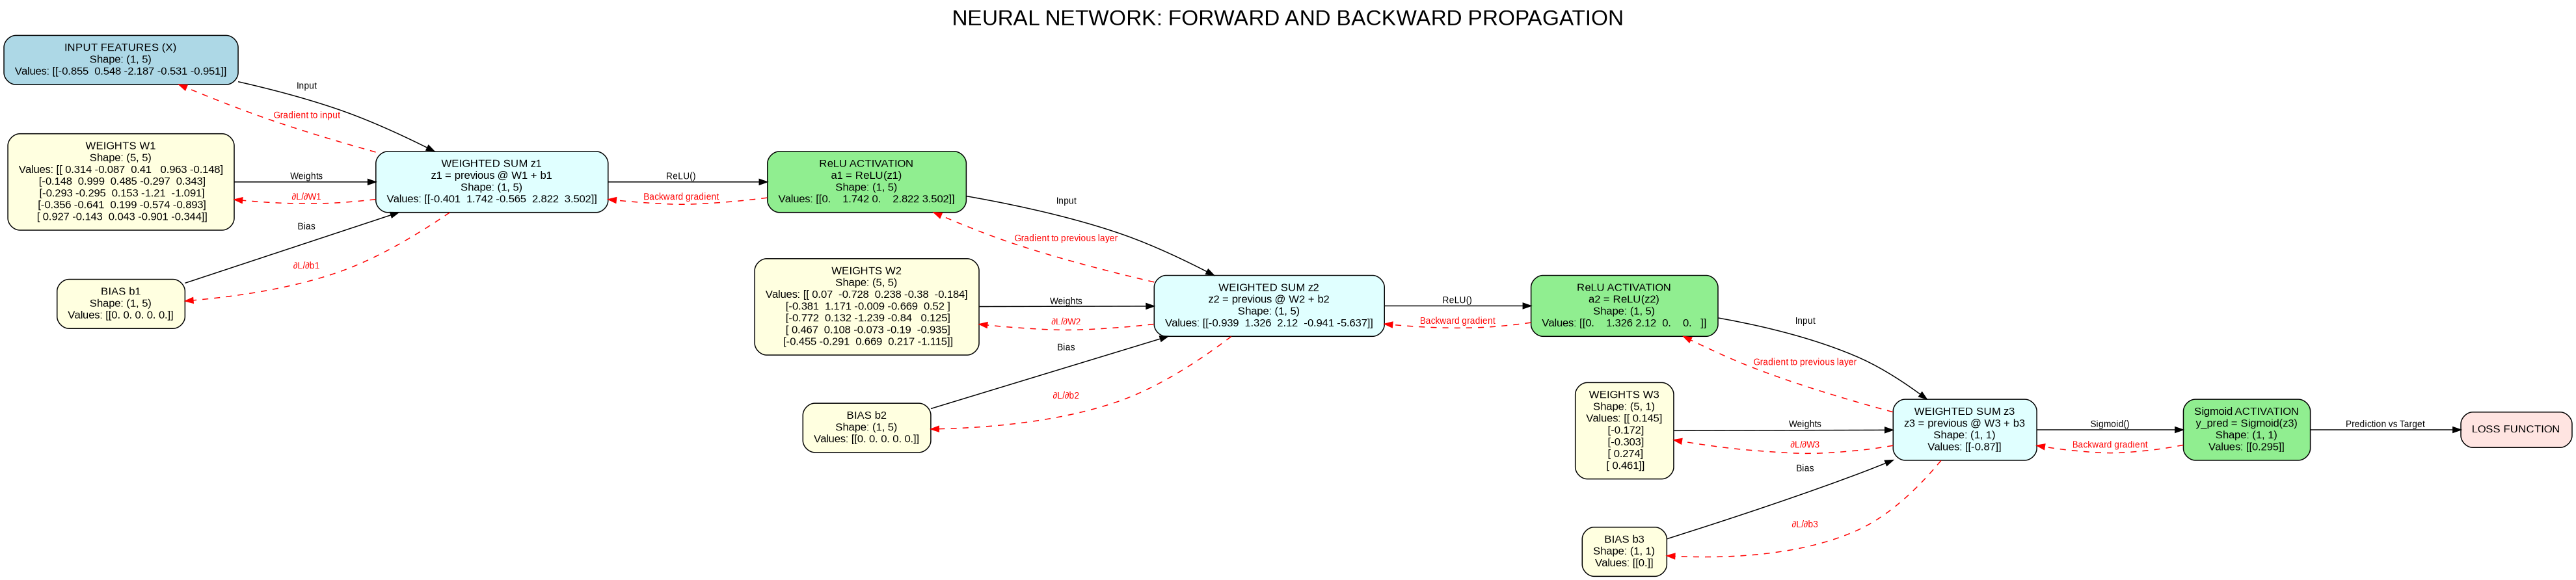

In [39]:
# Collect weights and biases in lists
weights = [w1, w2, w3]
biases = [b1, b2, b3]

# Run forward propagation for one patient
x_one = X_train[0:1]
predictions, cache = forward_pass(x_one)

# Visualise the neural network
dot = visualize_network(
    cache=cache,
    weights=weights,
    biases=biases,
    filename="patient_forward_backward",
    show_values=True,
    view=True
)

Graph saved successfully: corrected_forward_propagation.png


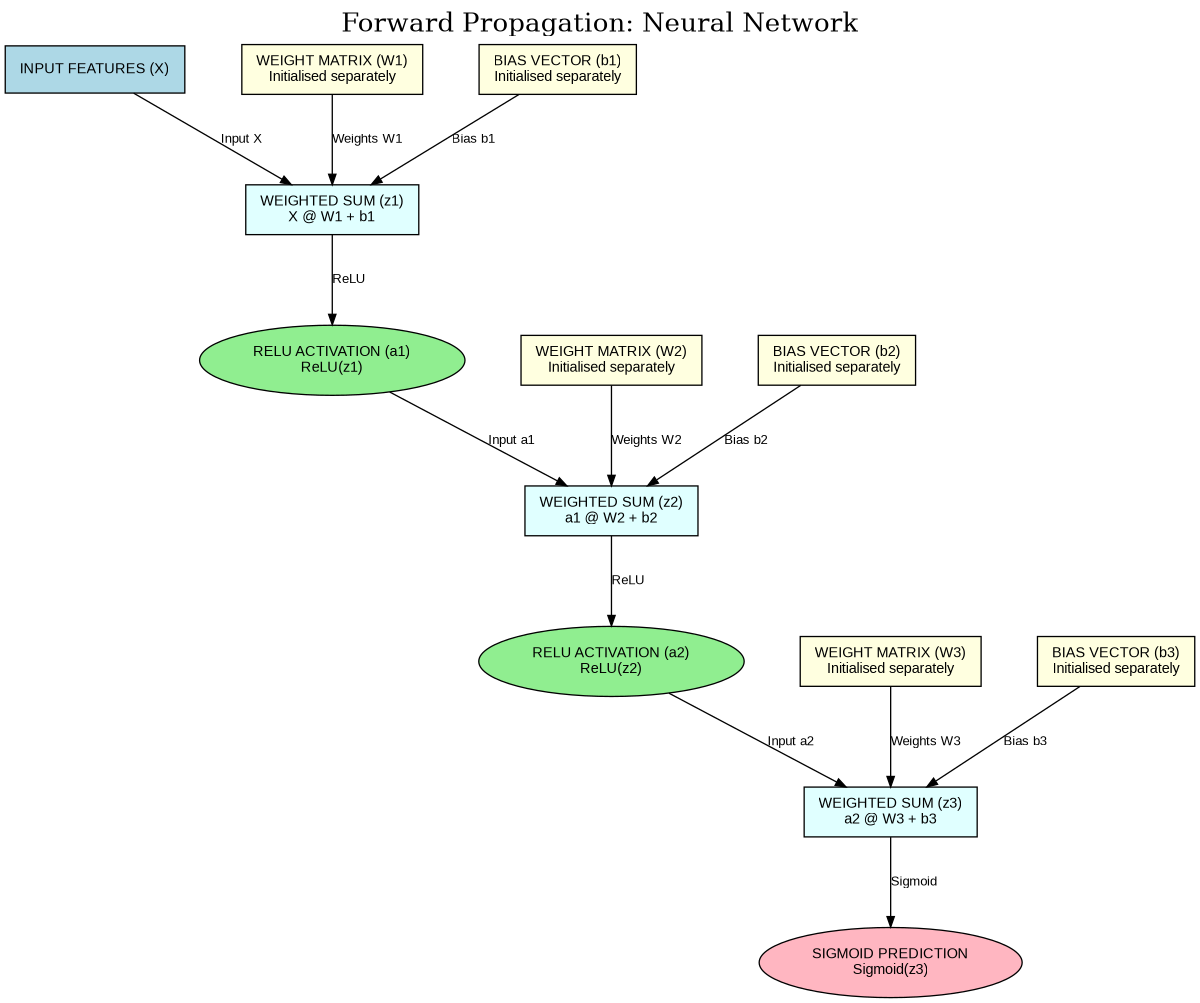

In [40]:

forward_steps = [

    # Input
    ("input", "INPUT FEATURES (X)", "box", "lightblue"),

    # First layer parameters
    ("W1", "WEIGHT MATRIX (W1)\nInitialised separately", "box", "lightyellow"),
    ("b1", "BIAS VECTOR (b1)\nInitialised separately", "box", "lightyellow"),

    # First layer computation
    ("z1", "WEIGHTED SUM (z1)\nX @ W1 + b1", "box", "lightcyan"),
    ("a1", "RELU ACTIVATION (a1)\nReLU(z1)", "ellipse", "lightgreen"),

    # Second layer parameters
    ("W2", "WEIGHT MATRIX (W2)\nInitialised separately", "box", "lightyellow"),
    ("b2", "BIAS VECTOR (b2)\nInitialised separately", "box", "lightyellow"),

    # Second layer computation
    ("z2", "WEIGHTED SUM (z2)\na1 @ W2 + b2", "box", "lightcyan"),
    ("a2", "RELU ACTIVATION (a2)\nReLU(z2)", "ellipse", "lightgreen"),

    # Output layer parameters
    ("W3", "WEIGHT MATRIX (W3)\nInitialised separately", "box", "lightyellow"),
    ("b3", "BIAS VECTOR (b3)\nInitialised separately", "box", "lightyellow"),

    # Output computation
    ("z3", "WEIGHTED SUM (z3)\na2 @ W3 + b3", "box", "lightcyan"),
    ("prediction", "SIGMOID PREDICTION\nSigmoid(z3)", "ellipse", "lightpink")
]


forward_edges = [

    # First layer: three separate inputs
    ("input", "z1", "Input X"),
    ("W1", "z1", "Weights W1"),
    ("b1", "z1", "Bias b1"),

    ("z1", "a1", "ReLU"),

    # Second layer: three separate inputs
    ("a1", "z2", "Input a1"),
    ("W2", "z2", "Weights W2"),
    ("b2", "z2", "Bias b2"),

    ("z2", "a2", "ReLU"),

    # Output layer: three separate inputs
    ("a2", "z3", "Input a2"),
    ("W3", "z3", "Weights W3"),
    ("b3", "z3", "Bias b3"),

    ("z3", "prediction", "Sigmoid")
]


forward_graph = visualise_flow(
    steps=forward_steps,
    edges=forward_edges,
    filename="corrected_forward_propagation",
    direction="TB",
    title="Forward Propagation: Neural Network",
    size="10,16"
)


What does `cache` mean?

During forward propagation, we save intermediate results.

Why?

Because backpropagation needs these values to calculate derivatives.

For example, to calculate the derivative of ReLU, we need the original \(z_1\) and \(z_2\).

Frameworks such as PyTorch maintain similar information in their computational graphs and autograd machinery.

### Calculate the Loss using Binary Cross-Entropy Formula

In [41]:
# Implement Binary Cross-Entropy
# L = 1/m Summation[y_i * log(y_pred_i) + (1 - y_i) * log(1 - y_pred_i)]

def binary_cross_entropy(y_true, y_pred):
    epsilon = 1e-12

    y_pred = np.clip(y_pred, epsilon, 1 - epsilon)
    loss = -np.mean(y_true * np.log(y_pred) + (1 - y_true) * np.log(1 - y_pred))
    return loss

In [42]:
# Calculate the loss for the first patient
loss_one = binary_cross_entropy(y_one, predictions)

print("Prediction:", predictions)
print("Actual:", y_one)
print("Loss:", loss_one)

Prediction: [[0.29521496]]
Actual: [0]
Loss: 0.34986242914896565


In [43]:
# From the above, we now have Input, forward propagation, activations, predictions, and loss
# The next question is: `How does the network know which weights and biases it should change?`
# This is where backpropagation comes in.

### Backpropagation for calculating the gradients
- Forward propagation answers the question: `Given the current weights and biases, what prediction does the network produce?`
- Backpropagation answers the question: `How much does the loss change when we change each weight and bias?`
- From this example, we want to calculate `dL/dw1`, `dL/db1`, `dL/dw2`, `dL/db2`, `dL/dw3`, `dL/db3`. These are the gradients.

Graph saved successfully: corrected_backward_propagation.png


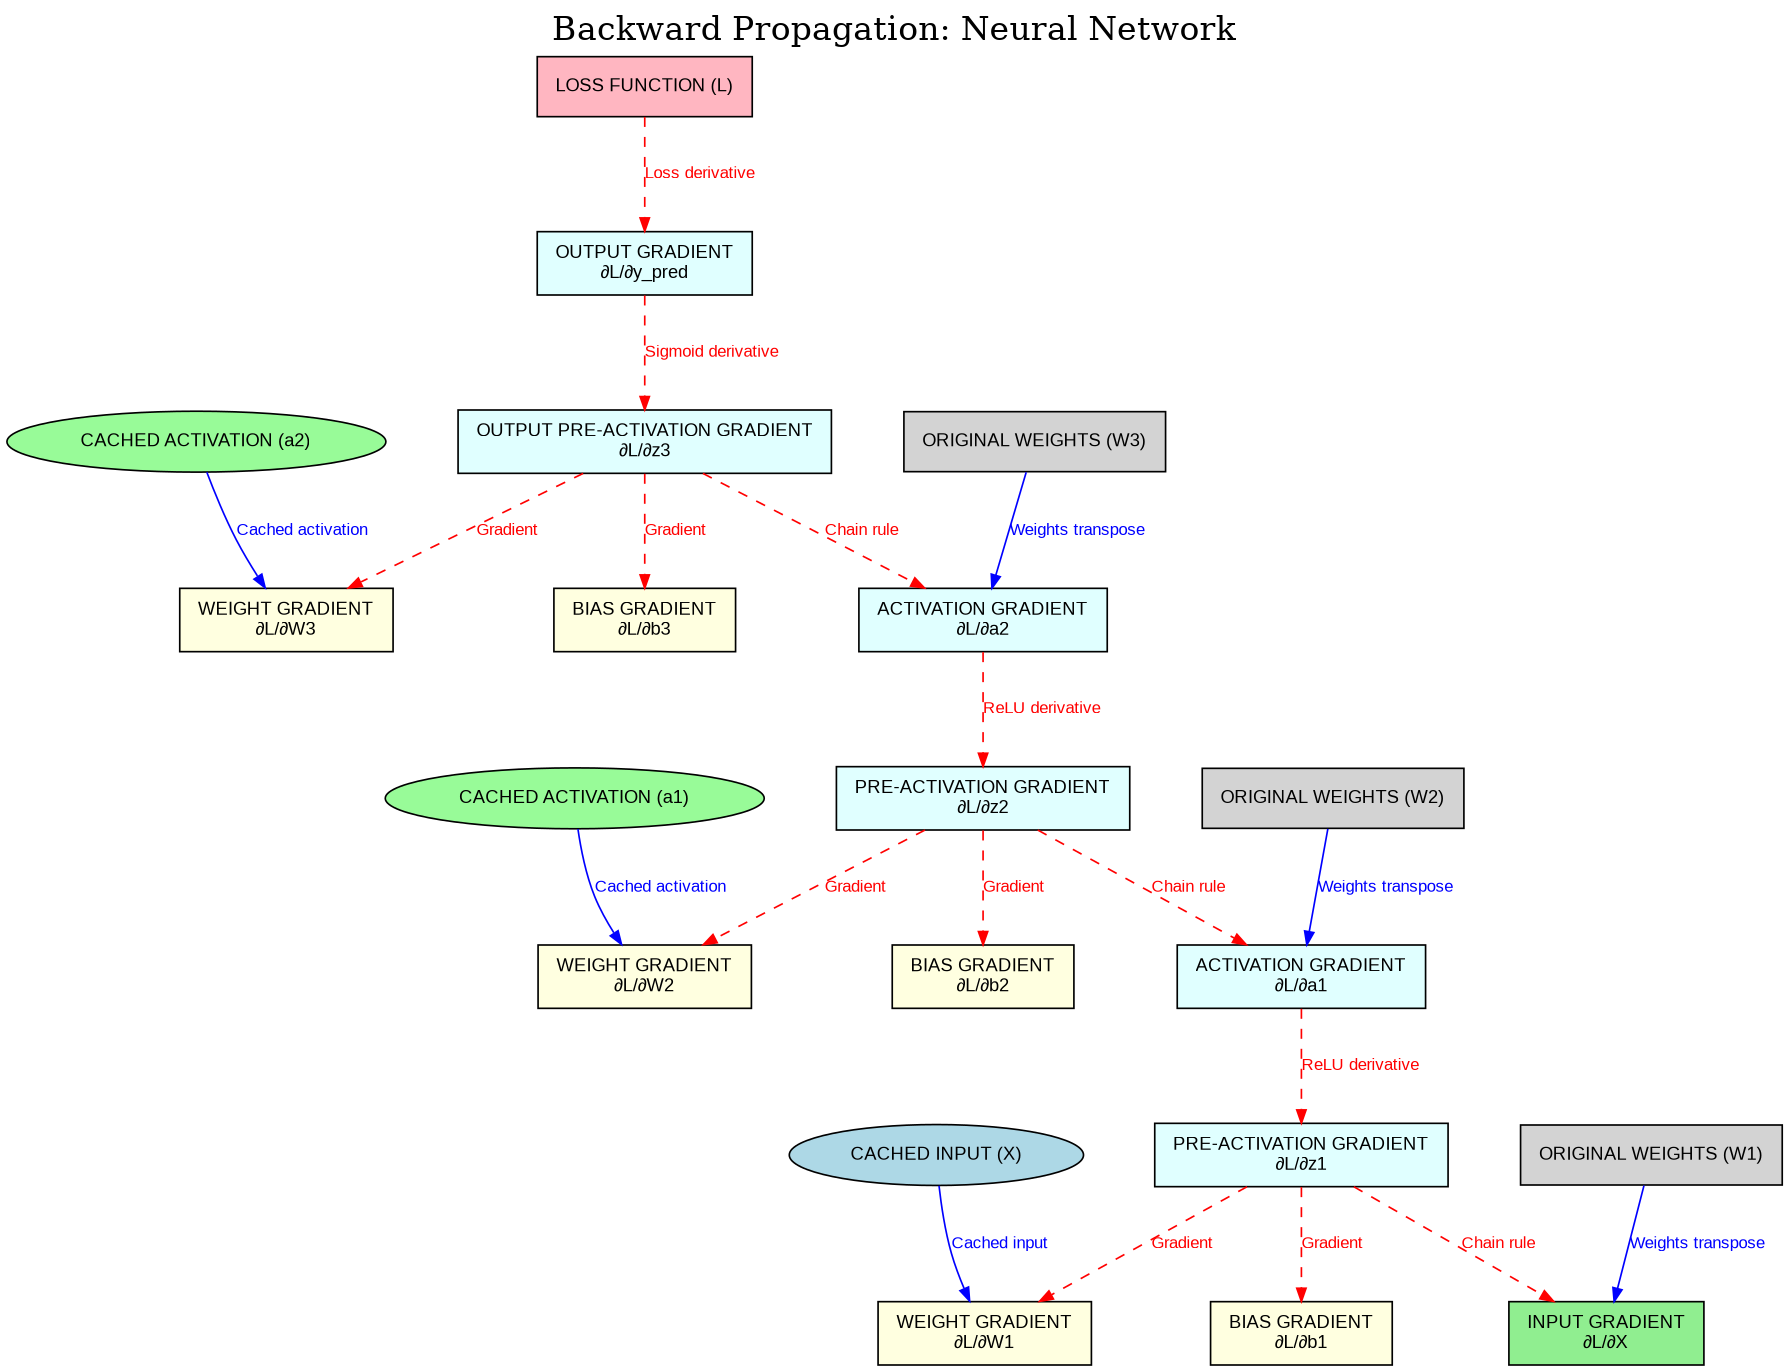

In [44]:

backward_steps = [

    # Loss
    ("loss", "LOSS FUNCTION (L)", "box", "lightpink"),

    # Output layer gradients
    ("dy_pred", "OUTPUT GRADIENT\n∂L/∂y_pred", "box", "lightcyan"),
    ("dz3", "OUTPUT PRE-ACTIVATION GRADIENT\n∂L/∂z3", "box", "lightcyan"),

    # Output layer parameter gradients
    ("dW3", "WEIGHT GRADIENT\n∂L/∂W3", "box", "lightyellow"),
    ("db3", "BIAS GRADIENT\n∂L/∂b3", "box", "lightyellow"),

    # Gradient flowing to second hidden layer
    ("da2", "ACTIVATION GRADIENT\n∂L/∂a2", "box", "lightcyan"),
    ("dz2", "PRE-ACTIVATION GRADIENT\n∂L/∂z2", "box", "lightcyan"),

    # Second layer parameter gradients
    ("dW2", "WEIGHT GRADIENT\n∂L/∂W2", "box", "lightyellow"),
    ("db2", "BIAS GRADIENT\n∂L/∂b2", "box", "lightyellow"),

    # Gradient flowing to first hidden layer
    ("da1", "ACTIVATION GRADIENT\n∂L/∂a1", "box", "lightcyan"),
    ("dz1", "PRE-ACTIVATION GRADIENT\n∂L/∂z1", "box", "lightcyan"),

    # First layer parameter gradients
    ("dW1", "WEIGHT GRADIENT\n∂L/∂W1", "box", "lightyellow"),
    ("db1", "BIAS GRADIENT\n∂L/∂b1", "box", "lightyellow"),

    # Input gradient
    ("dx", "INPUT GRADIENT\n∂L/∂X", "box", "lightgreen"),

    # Cached forward values
    ("a2", "CACHED ACTIVATION (a2)", "ellipse", "palegreen"),
    ("a1", "CACHED ACTIVATION (a1)", "ellipse", "palegreen"),
    ("X", "CACHED INPUT (X)", "ellipse", "lightblue"),

    # Original weights used in chain rule
    ("W3", "ORIGINAL WEIGHTS (W3)", "box", "lightgrey"),
    ("W2", "ORIGINAL WEIGHTS (W2)", "box", "lightgrey"),
    ("W1", "ORIGINAL WEIGHTS (W1)", "box", "lightgrey")
]


backward_edges = [

    # Loss to output gradient
    ("loss", "dy_pred", "Loss derivative", "red", "dashed"),

    # Sigmoid derivative
    ("dy_pred", "dz3", "Sigmoid derivative", "red", "dashed"),

    # Output layer gradients
    ("dz3", "dW3", "Gradient", "red", "dashed"),
    ("a2", "dW3", "Cached activation", "blue", "solid"),

    ("dz3", "db3", "Gradient", "red", "dashed"),

    # Gradient propagated to second hidden layer
    ("dz3", "da2", "Chain rule", "red", "dashed"),
    ("W3", "da2", "Weights transpose", "blue", "solid"),

    # ReLU derivative
    ("da2", "dz2", "ReLU derivative", "red", "dashed"),

    # Second layer gradients
    ("dz2", "dW2", "Gradient", "red", "dashed"),
    ("a1", "dW2", "Cached activation", "blue", "solid"),

    ("dz2", "db2", "Gradient", "red", "dashed"),

    # Gradient propagated to first hidden layer
    ("dz2", "da1", "Chain rule", "red", "dashed"),
    ("W2", "da1", "Weights transpose", "blue", "solid"),

    # ReLU derivative
    ("da1", "dz1", "ReLU derivative", "red", "dashed"),

    # First layer gradients
    ("dz1", "dW1", "Gradient", "red", "dashed"),
    ("X", "dW1", "Cached input", "blue", "solid"),

    ("dz1", "db1", "Gradient", "red", "dashed"),

    # Gradient propagated to input
    ("dz1", "dx", "Chain rule", "red", "dashed"),
    ("W1", "dx", "Weights transpose", "blue", "solid")
]


backward_graph = visualise_flow(
    steps=backward_steps,
    edges=backward_edges,
    filename="corrected_backward_propagation",
    direction="TB",
    title="Backward Propagation: Neural Network",
    size="16,24"
)


In [45]:
# Forward passs
predictions, cache = forward_pass(X_train)

In [46]:
X_train.shape

(579, 5)

In [47]:
cache["y_pred"].shape

(579, 1)

### Backpropagation Implementation in NumPy

In [48]:
# Backpropagation manually

In [49]:
# Retrive values saved during forward propagation
x = cache["x"]

z1 = cache["z1"]
a1 = cache["a1"]

z2 = cache["z2"]
a2 = cache["a2"]

y_pred = cache["y_pred"]

In [50]:
print(x)

[[-0.85530779  0.54771216 -2.18724279 -0.53067854 -0.95056927]
 [-0.85530779 -1.11827387 -0.85338608 -0.35771886 -0.86623283]
 [ 2.09244942 -0.36694684  0.98066688  2.07813     0.98916885]
 ...
 [ 1.20812226 -0.72627716  0.14700644  1.01154529  0.82049597]
 [ 0.91334654  0.48237937  1.48086315 -0.05503942  0.48315021]
 [ 1.7976737   0.22104823 -0.85338608  1.27098482  0.39881377]]


In [51]:
print(x.shape)

(579, 5)


In [52]:
y_pred.shape

(579, 1)

In [53]:
# Number of observations
m = y_pred.shape[0]
print(m)

579


In [54]:
y_pred.shape

(579, 1)

In [55]:
y_train.shape

(579,)

In [56]:
y_true = y_train.reshape(-1, 1)
y_true.shape

(579, 1)

In [57]:
# Output Layer
# dl/dz3
delta3 = (y_pred - y_true)/m
print("Shape of Delta3: ", delta3.shape)

Shape of Delta3:  (579, 1)


In [58]:
a2.shape

(579, 5)

In [59]:
a2.T.shape

(5, 579)

In [60]:
# dL/dw3
dW3 = a2.T @ delta3
print(dW3.shape)

(5, 1)


In [61]:
# dL/db3
db3 = np.sum(delta3, axis=0, keepdims=True)
print(db3.shape)

(1, 1)


### Second Hidden Layer

In [62]:
delta3.shape, w3.T.shape

((579, 1), (1, 5))

In [63]:
# # dL/da2
da2 = delta3 * w3.T
print(da2.shape)

(579, 5)


In [64]:
# Apply the hidden layer's Relu derivative
delta2 = da2 * relu_derivative(z2)
print(delta2.shape)

(579, 5)


In [65]:
# dL/dw2
dW2 = a1.T @ delta2
print(dW2.shape)

(5, 5)


In [66]:
# db2 = dL/db2
db2 = np.sum(delta2, axis=0, keepdims=True)
print(db2.shape)

(1, 5)


### First Hidden Layer

In [67]:
# dL/da1
da1 = delta2 @ w2.T
da1.shape

(579, 5)

In [68]:
delta1 = da1 * relu_derivative(z1)
print(delta1.shape)

(579, 5)


In [69]:
# dL/dw1
dW1 = x.T @ delta1
print(dW1.shape)

(5, 5)


In [70]:
db1 = np.sum(delta1, axis=1, keepdims=True)
print(db1.shape)

(579, 1)


In [71]:
# Return all gradients
gradients = {
    "dW1": dW1,
    "db1": db1,
    "dW2": dW2,
    "db2": db2,
    "dW3": dW3,
    "db3": db3
}
print(gradients)

{'dW1': array([[-2.07798734e-03,  4.32101238e-03,  4.97671927e-03,
         2.62775693e-03,  6.36311660e-03],
       [ 7.33769350e-05,  7.66780275e-03, -7.42950493e-03,
        -4.33884108e-03,  3.10890588e-02],
       [ 4.03144986e-04,  3.81192779e-03,  3.99240253e-03,
        -2.70890046e-03,  1.44621831e-02],
       [ 2.59370985e-03,  8.84610565e-03, -5.66769753e-03,
        -2.94686843e-03,  2.11287168e-02],
       [-4.10282396e-03,  9.29967563e-03,  6.99616904e-03,
        -2.54353410e-03,  1.26677764e-02]]), 'db1': array([[-1.77389993e-04],
       [-1.38095116e-04],
       [ 2.36121772e-05],
       [-1.01383349e-04],
       [ 3.91420709e-04],
       [ 2.72274683e-04],
       [ 1.59680804e-04],
       [-1.92644766e-04],
       [-6.36131771e-05],
       [ 2.56569499e-04],
       [-1.88027318e-04],
       [-2.42054862e-04],
       [ 3.00034413e-05],
       [-1.96563794e-04],
       [ 8.27211877e-05],
       [-2.62167869e-04],
       [-1.44454424e-04],
       [ 0.00000000e+00],
     

### Backpropagation: Putting everything in a function

In [72]:
def backward_pass(y_true, cache):
    # Retrive values saved during forward propagation
    x = cache["x"]

    z1 = cache["z1"]
    a1 = cache["a1"]

    z2 = cache["z2"]
    a2 = cache["a2"]

    y_pred = cache["y_pred"]

    # Number of observations
    m = y_true.shape[0]

    # Output Layer
    # dl/dz3
    delta3 = (y_pred - y_true.reshape(-1, 1))/m

    # dL/dw3
    dW3 = a2.T @ delta3

    # dL/db3
    db3 = np.sum(delta3, axis=0, keepdims=True)

    # # dL/da2
    da2 = delta3 @ w3.T

    # Apply the hidden layer's Relu derivative
    delta2 = da2 * relu_derivative(z2)

    # dL/dw2
    dW2 = a1.T @ delta2

    # db2 = dL/db2
    db2 = np.sum(delta2, axis=0, keepdims=True)

    # dL/da1
    da1 = delta2 @ w2.T

    delta1 = da1 * relu_derivative(z1)

    # dL/dw1
    dW1 = x.T @ delta1

    db1 = np.sum(delta1, axis=0, keepdims=True)

    # Return all gradients
    gradients = {
        "dW1": dW1,
        "db1": db1,
        "dW2": dW2,
        "db2": db2,
        "dW3": dW3,
        "db3": db3
    }

    return gradients

In [73]:
# Excute Backpropagation manually
# Here, we'll use our training observations to calculate the gradients


# Forward Pass
predictions, cache = forward_pass(X_train)
print(predictions.shape)
print(cache.keys())

(579, 1)
dict_keys(['x', 'z1', 'a1', 'z2', 'a2', 'z3', 'y_pred'])


In [74]:
cache["y_pred"].shape, y_train.shape

((579, 1), (579,))

In [75]:
# Compute Loss
loss = binary_cross_entropy(y_train, predictions)
print(loss.shape) # No diretion (scalar value)
print("Loss: ", loss) # A scalar value

()
Loss:  0.6801588444781406


In [76]:
# Compute Gradients
gradients = backward_pass(y_train, cache)
gradients

{'dW1': array([[-2.07798734e-03,  4.32101238e-03,  4.97671927e-03,
          2.62775693e-03,  6.36311660e-03],
        [ 7.33769350e-05,  7.66780275e-03, -7.42950493e-03,
         -4.33884108e-03,  3.10890588e-02],
        [ 4.03144986e-04,  3.81192779e-03,  3.99240253e-03,
         -2.70890046e-03,  1.44621831e-02],
        [ 2.59370985e-03,  8.84610565e-03, -5.66769753e-03,
         -2.94686843e-03,  2.11287168e-02],
        [-4.10282396e-03,  9.29967563e-03,  6.99616904e-03,
         -2.54353410e-03,  1.26677764e-02]]),
 'db1': array([[-0.00387799, -0.00730683,  0.00131384,  0.00853264, -0.01880471]]),
 'dW2': array([[ 4.07608577e-03,  4.05577036e-03, -1.66043635e-02,
          0.00000000e+00, -5.98703967e-03],
        [ 5.43498655e-04,  6.07943889e-03, -5.62394022e-03,
          6.81142081e-05, -1.49056697e-02],
        [ 3.93314357e-05,  9.43888367e-03,  3.04749050e-04,
          0.00000000e+00, -2.10662064e-02],
        [ 1.74670886e-02, -1.21073117e-02, -5.62779225e-02,
        

In [77]:
for name, gradient in gradients.items():
    print(f"\n{name}")
    print(gradient)
    print("Shape: ", gradient.shape)


dW1
[[-2.07798734e-03  4.32101238e-03  4.97671927e-03  2.62775693e-03
   6.36311660e-03]
 [ 7.33769350e-05  7.66780275e-03 -7.42950493e-03 -4.33884108e-03
   3.10890588e-02]
 [ 4.03144986e-04  3.81192779e-03  3.99240253e-03 -2.70890046e-03
   1.44621831e-02]
 [ 2.59370985e-03  8.84610565e-03 -5.66769753e-03 -2.94686843e-03
   2.11287168e-02]
 [-4.10282396e-03  9.29967563e-03  6.99616904e-03 -2.54353410e-03
   1.26677764e-02]]
Shape:  (5, 5)

db1
[[-0.00387799 -0.00730683  0.00131384  0.00853264 -0.01880471]]
Shape:  (1, 5)

dW2
[[ 4.07608577e-03  4.05577036e-03 -1.66043635e-02  0.00000000e+00
  -5.98703967e-03]
 [ 5.43498655e-04  6.07943889e-03 -5.62394022e-03  6.81142081e-05
  -1.49056697e-02]
 [ 3.93314357e-05  9.43888367e-03  3.04749050e-04  0.00000000e+00
  -2.10662064e-02]
 [ 1.74670886e-02 -1.21073117e-02 -5.62779225e-02  2.20806577e-03
  -5.77668453e-04]
 [ 1.06639223e-02 -9.55145857e-03 -4.54955205e-02  2.48644009e-03
  -2.38900110e-03]]
Shape:  (5, 5)

db2
[[ 0.01166388 -0.00

### Gradient Descent for Updating the Weights and Biases

In [78]:
#theta_new = theta_old - n * (dL/d theta)
# where theta represents a traininable parameter, n is the learning rate and (dL/d theta is its gradient)

In [79]:
# Implement Gradient Descent
learning_rate = 0.01

In [80]:
gradients["db1"] * 0.01

array([[-3.87798635e-05, -7.30682643e-05,  1.31383916e-05,
         8.53264141e-05, -1.88047077e-04]])

In [81]:
# This function implements the gradient descent update equation six times: once for each weight and bias array.
# Notice that we are modifying the original parameters
# We are not creating a new neural network

def update_parameters(gradients, learning_rate):
    global w1, b1
    global w2, b2
    global w3, b3

    # Update first layer parameters
    w1 -= learning_rate * gradients["dW1"]
    b1 -= learning_rate * gradients["db1"]

    # Update second layer parameters
    w2 -= learning_rate * gradients["dW2"]
    b2 -= learning_rate * gradients["db2"]

    # Update output layer parameters
    w3 -= learning_rate * gradients["dW3"]
    b3 -= learning_rate * gradients["db3"]


#### Now Put Forward Propagation, Backpropagation and Gradient Descent Together
*From the above, we now have the necessary building blocks*

The training process is:
1. Forward propagation
2. Calculate loss
3. Backpropagation
4. Calculate gradients
5. Update parameters
6. Repeat

Once complete execution of these steps is called a training iteration.
*When we pass the entire training dataset through the network before updating the parameters, we are performing full-batch gradient descent*

### Train the Network

In [82]:
# epochs = 10000
# learning_rate = 0.001

# loss_history = []

# for epoch in range(epochs):

#     # STEP 1: Forward propagation
#     y_pred, cache = forward_pass(X_train)


#     # STEP 2: Compute Loss
#     loss = binary_cross_entropy(y_train, y_pred)

#     # STEP 3: Backpropagation
#     gradients = backward_pass(y_train, cache)

#     # STEP 4: Update Parameters
#     update_parameters(gradients, learning_rate)

#     loss_history.append(loss)

#     # Display progress
#     if (epoch + 1) % 100 == 0:
#         print(
#             f"Epoch {epoch + 1}/ {epochs}, " f"Loss: {loss:.6f}"
#         )

In [83]:

epochs = 10000
learning_rate = 0.001

loss_history = []

for epoch in range(epochs):

    # STEP 1: Forward propagation
    y_pred, cache = forward_pass(X_train)

    # STEP 2: Calculate loss
    loss = binary_cross_entropy(y_train, y_pred)

    # STEP 3: Backpropagation
    gradients = backward_pass(y_train, cache)

    # STEP 4: Update parameters
    update_parameters(gradients, learning_rate)

    loss_history.append(loss)

    # Display progress
    if (epoch + 1) % 100 == 0:

        print(
            f"Epoch {epoch + 1}/{epochs}, "
            f"Loss: {loss:.6f}"
        )


Epoch 100/10000, Loss: 0.678221
Epoch 200/10000, Loss: 0.676416
Epoch 300/10000, Loss: 0.674759
Epoch 400/10000, Loss: 0.673246
Epoch 500/10000, Loss: 0.671877
Epoch 600/10000, Loss: 0.670650
Epoch 700/10000, Loss: 0.669567
Epoch 800/10000, Loss: 0.668630
Epoch 900/10000, Loss: 0.667835
Epoch 1000/10000, Loss: 0.667173
Epoch 1100/10000, Loss: 0.666644
Epoch 1200/10000, Loss: 0.666245
Epoch 1300/10000, Loss: 0.665974
Epoch 1400/10000, Loss: 0.665825
Epoch 1500/10000, Loss: 0.665801
Epoch 1600/10000, Loss: 0.665893
Epoch 1700/10000, Loss: 0.666097
Epoch 1800/10000, Loss: 0.666405
Epoch 1900/10000, Loss: 0.666811
Epoch 2000/10000, Loss: 0.667314
Epoch 2100/10000, Loss: 0.667903
Epoch 2200/10000, Loss: 0.668572
Epoch 2300/10000, Loss: 0.669314
Epoch 2400/10000, Loss: 0.670130
Epoch 2500/10000, Loss: 0.671015
Epoch 2600/10000, Loss: 0.671967
Epoch 2700/10000, Loss: 0.672973
Epoch 2800/10000, Loss: 0.674038
Epoch 2900/10000, Loss: 0.675153
Epoch 3000/10000, Loss: 0.676314
Epoch 3100/10000, L

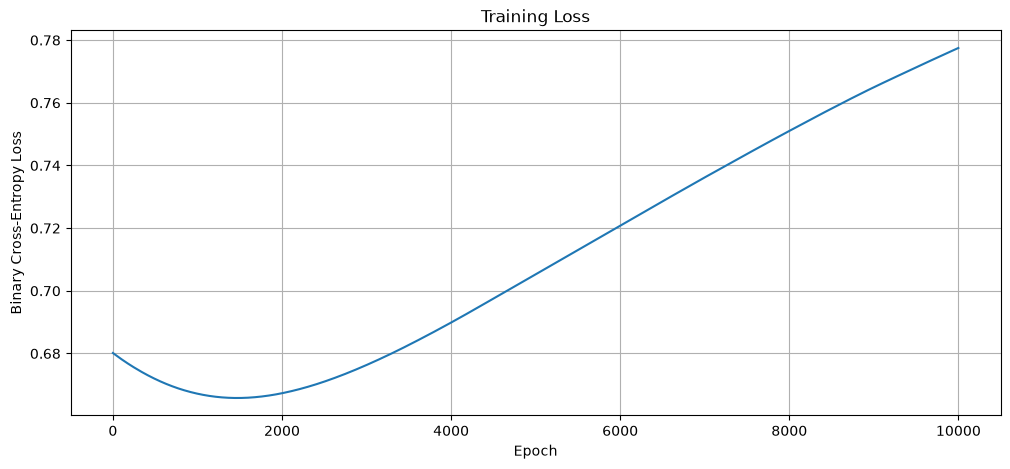

In [84]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(loss_history)

plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")

plt.title("Training Loss")

plt.grid(True)
plt.show()